In [10]:
#%pip install scipy

In [11]:
import numpy as np
import pandas as pd
from scipy import stats

df = pd.read_csv("../dados/base_quedas_AACD_anonimizada.csv")

# Cópia para não alterar o df original
df_clean = df.copy()

# 1. Padronizar "não informado" (ignorando maiúsculas/minúsculas e espaços) para NaN
df_clean = df_clean.replace(
    to_replace=r'(?i)^\s*não informado\s*$', value=np.nan, regex=True
)

# 2. Preparar "Queda último mês" (binária: sim=1, não=0)
col_bin = 'Queda último mês'
df_clean[col_bin] = (
    df_clean[col_bin]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({'sim': 1, 'não': 0})
)

# 3. Preparar "Nº quedas ao chão" (numérica >= 0)
col_num = 'Nº quedas ao chão'
df_clean[col_num] = pd.to_numeric(df_clean[col_num], errors='coerce')

In [ ]:
def cramers_v_np(x, y):
  ct = pd.crosstab(x, y)
  if ct.shape[0] < 2 or ct.shape[1] < 2:
    return np.nan
  obs = ct.to_numpy()
  n = obs.sum()
  expected = np.outer(obs.sum(axis=1), obs.sum(axis=0)) / n
  chi2 = ((obs - expected) ** 2 / expected).sum()
  phi2 = chi2 / n
  r, k = obs.shape
  phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
  rcorr = r - ((r - 1) ** 2) / (n - 1)
  kcorr = k - ((k - 1) ** 2) / (n - 1)
  denom = min((kcorr - 1), (rcorr - 1))
  return np.sqrt(phi2corr / denom) if denom > 0 else np.nan


def eta_squared_np(cat_series, num_series):
  df_tmp = pd.DataFrame({'cat': cat_series, 'num': num_series}).dropna()
  if df_tmp['cat'].nunique() < 2 or len(df_tmp) < 3:
    return np.nan
  grand_mean = df_tmp['num'].mean()
  ss_total = ((df_tmp['num'] - grand_mean) ** 2).sum()
  if ss_total == 0:
    return 0.0
  ss_between = sum(
      len(g) * (g['num'].mean() - grand_mean) ** 2
      for _, g in df_tmp.groupby('cat')
  )
  return ss_between / ss_total


resultados = []
ignorar = [col_bin, col_num, 'ID', 'Custo dupla tarefa', "Braço D", "Braço E", "Aditamento 10m"]

for col in df_clean.columns:
  if col in ignorar:
    continue

  is_numeric = pd.api.types.is_numeric_dtype(df_clean[col])
  tipo = 'Numérica' if is_numeric else 'Categórica'

  # --- Relação 1: com "Queda último mês" ---
  sub1 = df_clean[[col, col_bin]].dropna()
  if len(sub1) > 5 and sub1[col_bin].nunique() == 2:
    if is_numeric:
      r1 = sub1[col].corr(sub1[col_bin], method='pearson')
      metrica1 = f'r = {r1:.3f}'
      forca1 = abs(r1)
    else:
      v1 = cramers_v_np(sub1[col], sub1[col_bin])
      metrica1 = f'V = {v1:.3f}'
      forca1 = v1
  else:
    metrica1, forca1 = 'N/A', np.nan

  # --- Relação 2: com "Nº quedas ao chão" ---
  sub2 = df_clean[[col, col_num]].dropna()
  if len(sub2) > 5:
    if is_numeric:
      rho2 = sub2[col].corr(sub2[col_num], method='spearman')
      metrica2 = f'rho = {rho2:.3f}'
      forca2 = abs(rho2)
    else:
      eta2 = eta_squared_np(sub2[col], sub2[col_num])
      metrica2 = f'eta2 = {eta2:.3f}'
      forca2 = eta2
  else:
    metrica2, forca2 = 'N/A', np.nan

  resultados.append({
      'Coluna': col,
      'Tipo': tipo,
      'Relação_Queda_Mes': metrica1,
      'Forca_Queda_Mes': round(forca1, 3) if pd.notna(forca1) else np.nan,
      'Relação_Num_Quedas': metrica2,
      'Forca_Num_Quedas': round(forca2, 3) if pd.notna(forca2) else np.nan,
  })

resumo = pd.DataFrame(resultados).sort_values(
    by='Forca_Queda_Mes', ascending=False
)
print(resumo.to_string(index=False))

                      Coluna       Tipo Relação_Queda_Mes  Forca_Queda_Mes Relação_Num_Quedas  Forca_Num_Quedas
                       Idade   Numérica         r = 0.203            0.203        rho = 0.092             0.092
          Objetos de auxílio Categórica         V = 0.165            0.165       eta2 = 0.133             0.133
            Velocidade (m/s)   Numérica        r = -0.123            0.123       rho = -0.122             0.122
              Aditamento 10m Categórica         V = 0.122            0.122       eta2 = 0.332             0.332
            Cogniçao (10-CS)   Numérica         r = 0.119            0.119        rho = 0.166             0.166
          Posição equilíbrio Categórica         V = 0.109            0.109       eta2 = 0.012             0.012
                Polifarmácia Categórica         V = 0.106            0.106       eta2 = 0.001             0.001
          Nivel de locomoção Categórica         V = 0.090            0.090       eta2 = 0.008           

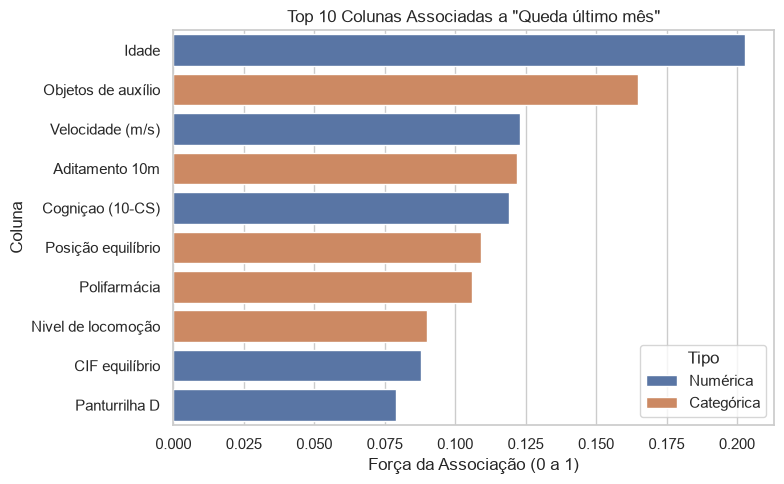

C:\Users\41228408807\AppData\Local\Temp\ipykernel_13356\3157424002.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Não (0)', 'Sim (1)'])


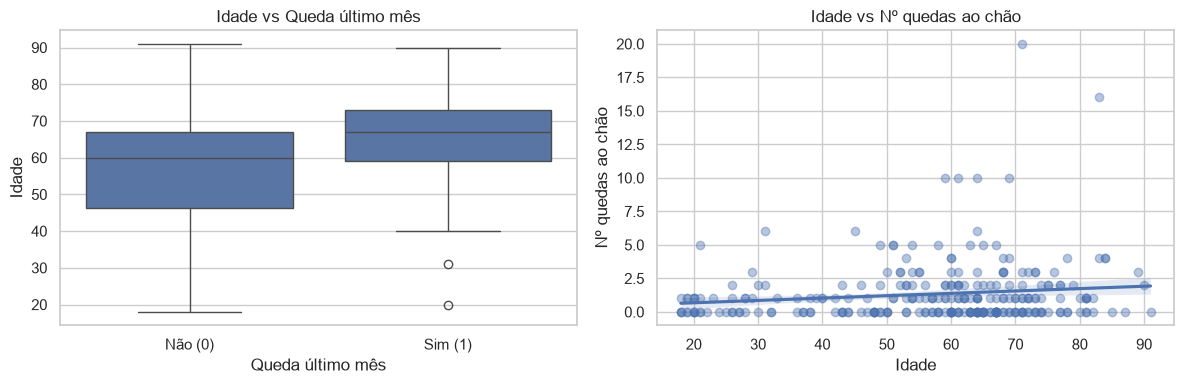

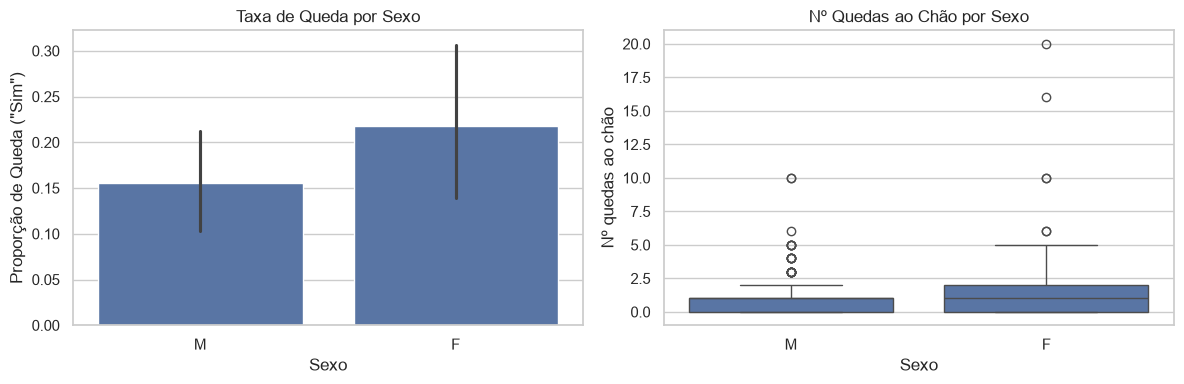

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

# Exemplo A: Ranking geral das forças de associação com "Queda último mês"
top_cols = resumo.dropna(subset=['Forca_Queda_Mes']).head(10)
plt.figure(figsize=(8, 5))
sns.barplot(
    data=top_cols, x='Forca_Queda_Mes', y='Coluna', hue='Tipo', dodge=False
)
plt.title('Top 10 Colunas Associadas a "Queda último mês"')
plt.xlabel('Força da Associação (0 a 1)')
plt.tight_layout()
plt.show()

# Exemplo B: Detalhar uma coluna NUMÉRICA (ex: "Idade") vs os dois alvos
col_exemplo_num = 'Idade'  # substitua pelo nome real
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df_clean, x=col_bin, y=col_exemplo_num, ax=axes[0])
axes[0].set_xticklabels(['Não (0)', 'Sim (1)'])
axes[0].set_title(f'{col_exemplo_num} vs Queda último mês')

sns.regplot(
    data=df_clean,
    x=col_exemplo_num,
    y=col_num,
    ax=axes[1],
    scatter_kws={'alpha': 0.4},
)
axes[1].set_title(f'{col_exemplo_num} vs Nº quedas ao chão')
plt.tight_layout()
plt.show()

# Exemplo C: Detalhar uma coluna CATEGÓRICA (ex: "Sexo") vs os dois alvos
col_exemplo_cat = 'Sexo'  # substitua pelo nome real
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Proporção de "Sim" por categoria
sns.barplot(data=df_clean, x=col_exemplo_cat, y=col_bin, ax=axes[0])
axes[0].set_ylabel('Proporção de Queda ("Sim")')
axes[0].set_title(f'Taxa de Queda por {col_exemplo_cat}')

# Média e dispersão do Nº de quedas por categoria
sns.boxplot(data=df_clean, x=col_exemplo_cat, y=col_num, ax=axes[1])
axes[1].set_title(f'Nº Quedas ao Chão por {col_exemplo_cat}')
plt.tight_layout()
plt.show()